# 🛍️ Customer Segmentation with K-Means

**Clustering project: K-Means + Calinski-Harabasz (CH) Index + Adjusted Rand Index (ARI)**

---

## 📌 Business problem
A retail company has thousands of customers and wants to treat them differently
(e.g. reward loyal ones, win back customers who are drifting away).
Nobody has labelled the customers in advance, so we use **unsupervised learning (clustering)**
to discover natural customer groups. This is called **customer segmentation** and it is one of the
most common real-world uses of K-Means.

## 🎯 What this notebook does
| Step | What we do | Why |
|---|---|---|
| 1 | Create RFM-style customer data | Recency, Frequency, Monetary is the classic marketing feature set |
| 2 | Scale the features | K-Means uses distances, so features must be on the same scale |
| 3 | Run K-Means for many values of K | We don't know the right number of groups |
| 4 | Plot **CH Index vs K** | Pick the K with the highest CH score (internal validation) |
| 5 | Fit the final model | Using the best K |
| 6 | Compute **Adjusted Rand Index** | Compare clusters with the known truth (external validation) |
| 7 | Visualise and profile the segments | Turn clusters into business insight |

## 📖 Key concepts in one minute
- **K-Means**: picks K centres, assigns each point to its nearest centre, moves centres to the mean of their points, and repeats until stable.
- **Calinski-Harabasz (CH) Index** *(internal validation, needs no labels)*: ratio of *between-cluster spread* to *within-cluster spread*. **Higher = better** (compact and well separated clusters).
- **Adjusted Rand Index (ARI)** *(external validation, needs true labels)*: how well the clusters agree with the true groups. **1 = perfect match, about 0 = random, negative = worse than random.**

## 1️⃣ Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA

# Reproducibility and nicer plots
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\Asus\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\Asus\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\Asus\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\Asus\anaconda3\Lib\site-packages\

AttributeError: _ARRAY_API not found

## 2️⃣ Create the customer dataset

We use **RFM features**, the standard way retailers describe customer behaviour:

- **Recency**: days since the last purchase (lower is better)
- **Frequency**: number of orders per year
- **Monetary**: total amount spent per year

> 💡 **Why synthetic data?**
> Real customers come without "true" segment labels, so ARI could not be computed.
> Here we *generate* customers from 4 known segments so we can check how well K-Means rediscovers them.
> In the clustering step we **pretend we don't know these labels**. They are only used at the very end for ARI.
> To use your own data, replace this cell with `pd.read_csv(...)` and keep the three RFM columns.

In [3]:
# Each segment: (name, n_customers, (mean, std) for Recency, Frequency, Monetary)
segment_profiles = {
    "Champions":   (300, (10, 5),   (40, 8),  (4000, 600)),
    "Loyal":       (350, (30, 10),  (20, 5),  (1800, 400)),
    "At Risk":     (250, (120, 25), (8, 3),   (700, 200)),
    "Lost":        (300, (250, 40), (2, 1),   (150, 60)),
}

frames = []
for name, (n, rec, freq, mon) in segment_profiles.items():
    frames.append(pd.DataFrame({
        "Recency":   np.random.normal(rec[0],  rec[1],  n),
        "Frequency": np.random.normal(freq[0], freq[1], n),
        "Monetary":  np.random.normal(mon[0],  mon[1],  n),
        "true_segment": name,
    }))

df = pd.concat(frames, ignore_index=True)

# Keep values realistic (no negative days/orders/spend)
df[["Recency", "Frequency", "Monetary"]] = df[["Recency", "Frequency", "Monetary"]].clip(lower=1)

# Shuffle rows so segments are not stored in order
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
df.head()

,Recency,Frequency,Monetary,true_segment
0,271.739175,2.079598,101.077462,Lost
1,94.622645,8.814486,426.572439,At Risk
2,7.896773,35.205000,4629.405536,Champions
3,40.470983,16.232911,2484.245349,Loyal
4,11.656317,42.581748,4118.850856,Champions


## 3️⃣ Quick look at the data

In [4]:
print("Shape:", df.shape)
df[["Recency", "Frequency", "Monetary"]].describe().round(1)

Shape: (1200, 4)


,Recency,Frequency,Monetary
count,1200.0,1200.0,1200.0
mean,99.0,18.0,1730.0
std,98.7,15.1,1526.1
min,1.0,1.0,1.0
25%,16.3,3.6,286.3
50%,41.7,14.9,1418.3
75%,165.4,28.3,2752.1
max,407.0,64.6,5579.4


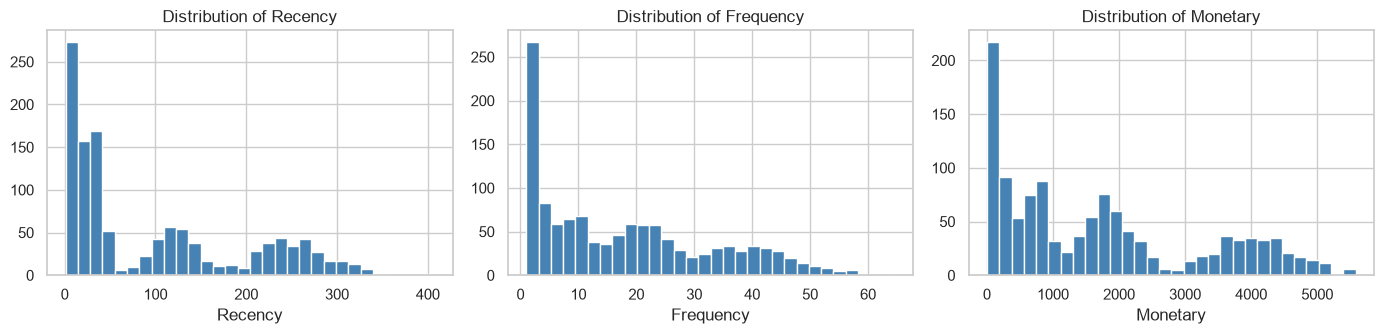

In [6]:
# The three features live on very different scales (Monetary is in the thousands, Frequency in tens)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

## 4️⃣ Prepare the features

K-Means measures **Euclidean distance**. Without scaling, `Monetary` (values in the thousands) would
completely dominate `Frequency` (values in the tens). `StandardScaler` rescales every feature to
mean 0 and standard deviation 1.

We keep the true labels **out of** the feature matrix `X`. The model never sees them.

In [7]:
features = ["Recency", "Frequency", "Monetary"]

X = df[features].values
y_true = df["true_segment"].values   # used ONLY for external validation at the end

X_scaled = StandardScaler().fit_transform(X)
print("Mean after scaling:", X_scaled.mean(axis=0).round(2))
print("Std  after scaling:", X_scaled.std(axis=0).round(2))

Mean after scaling: [0. 0. 0.]
Std  after scaling: [1. 1. 1.]


## 5️⃣ Choose K using the Calinski-Harabasz (CH) Index

We don't know how many segments exist, so we try K = 2 to 10 and compute the CH score for each.

$$CH = \frac{\text{between-cluster dispersion}/(K-1)}{\text{within-cluster dispersion}/(N-K)}$$

**Rule of thumb:** choose the K where the CH curve reaches its **maximum**.

> ⚠️ Unlike the "elbow" method (inertia), CH has a clear peak, so choosing K is less subjective.

In [8]:
k_values = range(2, 11)
ch_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))

ch_table = pd.DataFrame({"K": list(k_values), "CH_Index": ch_scores})
ch_table.round(1)

,K,CH_Index
0,2,2483.0
1,3,3430.3
2,4,5062.8
3,5,4730.3
4,6,4377.4
5,7,4241.3
6,8,4184.1
7,9,4032.4
8,10,3914.6


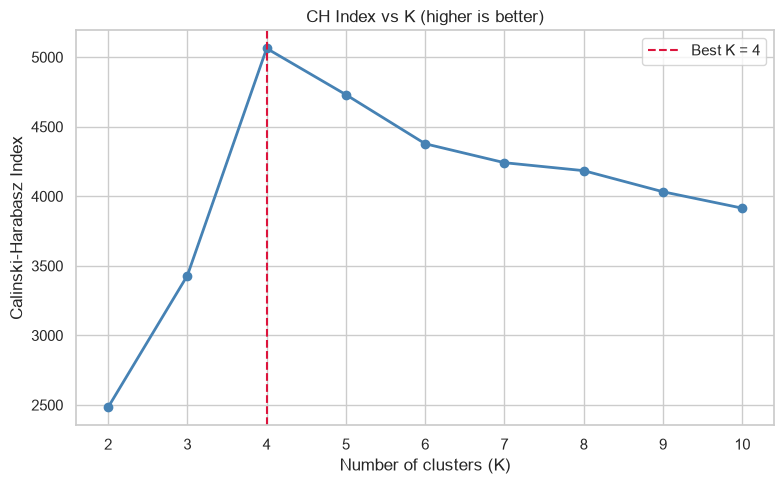

✅ CH Index is highest at K = 4


In [9]:
best_k = ch_table.loc[ch_table["CH_Index"].idxmax(), "K"]

plt.figure(figsize=(8, 5))
plt.plot(ch_table["K"], ch_table["CH_Index"], marker="o", linewidth=2, color="steelblue")
plt.axvline(best_k, color="crimson", linestyle="--", label=f"Best K = {best_k}")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Calinski-Harabasz Index")
plt.title("CH Index vs K (higher is better)")
plt.xticks(list(k_values))
plt.legend()
plt.tight_layout()
plt.show()

print(f"✅ CH Index is highest at K = {best_k}")

## 6️⃣ Fit the final K-Means model

We now train K-Means with the K picked by the CH index.
`n_init=10` runs the algorithm 10 times with different random starting centres and keeps the best result,
which avoids unlucky initialisation.

In [10]:
final_model = KMeans(n_clusters=int(best_k), n_init=10, random_state=RANDOM_STATE)
df["cluster"] = final_model.fit_predict(X_scaled)

df["cluster"].value_counts().sort_index()

cluster
0    297
1    287
2    352
3    264
Name: count, dtype: int64

## 7️⃣ External validation with Adjusted Rand Index (ARI)

CH tells us the clusters are compact and separated, but **do they match the real segments?**
ARI compares our cluster labels to the true labels by counting pairs of customers that are grouped together (or apart) in both.

| ARI | Meaning |
|---|---|
| 1.0 | Perfect agreement |
| ≈ 0 | Random labelling |
| < 0 | Worse than random |

✅ ARI does **not** care about the cluster numbers (cluster `0` may correspond to "Lost"). Only the grouping matters.

In [11]:
ari = adjusted_rand_score(y_true, df["cluster"])
print(f"Adjusted Rand Index (K={best_k}): {ari:.3f}")

Adjusted Rand Index (K=4): 0.965


In [12]:
# How do clusters map to the true segments? (rows = true segment, columns = cluster id)
pd.crosstab(df["true_segment"], df["cluster"])

cluster,0,1,2,3
true_segment,,,,
At Risk,0,0,0,250
Champions,297,0,3,0
Lost,0,287,0,13
Loyal,0,0,349,1


### Bonus: does the CH-best K also give the best ARI?
In real projects you cannot compute ARI (no labels), so it's reassuring to see that the **internal** metric (CH) and the **external** metric (ARI) agree.

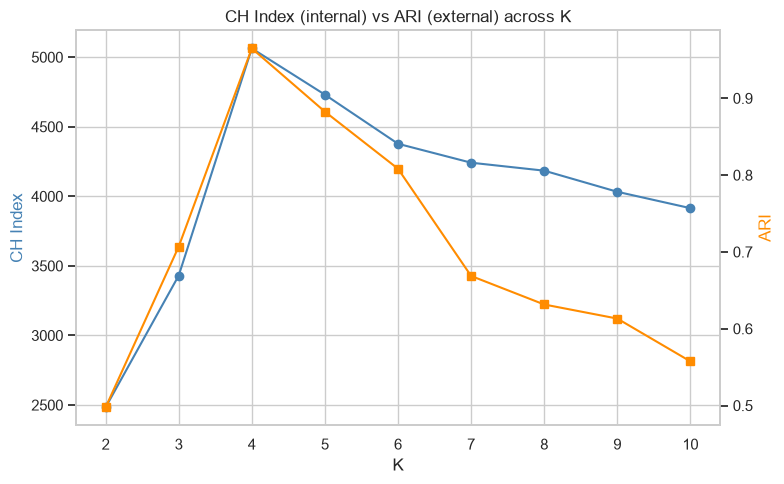

In [13]:
ari_scores = []
for k in k_values:
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    ari_scores.append(adjusted_rand_score(y_true, labels))

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(list(k_values), ch_scores, marker="o", color="steelblue", label="CH Index")
ax1.set_xlabel("K")
ax1.set_ylabel("CH Index", color="steelblue")

ax2 = ax1.twinx()
ax2.plot(list(k_values), ari_scores, marker="s", color="darkorange", label="ARI")
ax2.set_ylabel("ARI", color="darkorange")
ax2.grid(False)

plt.title("CH Index (internal) vs ARI (external) across K")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

## 8️⃣ Visualise the clusters

Our data has 3 features, so we use **PCA** to squash it into 2D for plotting.
Left: clusters found by K-Means. Right: the true segments. If they look alike, the model did a good job.

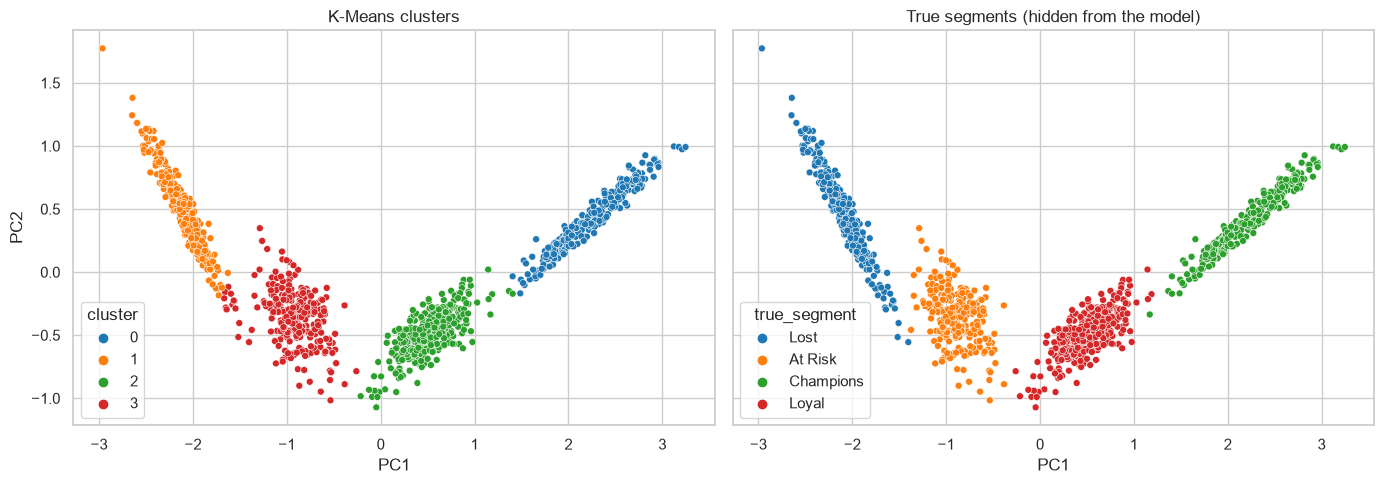

Variance explained by 2 PCs: 97.1%


In [14]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
df["PC1"], df["PC2"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
sns.scatterplot(data=df, x="PC1", y="PC2", hue="cluster", palette="tab10", s=25, ax=axes[0])
axes[0].set_title("K-Means clusters")
sns.scatterplot(data=df, x="PC1", y="PC2", hue="true_segment", palette="tab10", s=25, ax=axes[1])
axes[1].set_title("True segments (hidden from the model)")
plt.tight_layout()
plt.show()

print(f"Variance explained by 2 PCs: {pca.explained_variance_ratio_.sum():.1%}")

## 9️⃣ Turn clusters into business insight

A cluster number means nothing to a marketing team. We **profile** each cluster by its average RFM values
and give it a human-friendly name.

In [15]:
profile = df.groupby("cluster")[features].mean().round(1)
profile["customers"] = df["cluster"].value_counts().sort_index()
profile

,Recency,Frequency,Monetary,customers
cluster,,,,
0,10.0,40.0,4058.4,297
1,254.7,2.0,153.8,287
2,30.6,20.3,1835.0,352
3,121.2,7.7,684.3,264


In [16]:
# Name each cluster automatically from its profile:
# best monetary -> Champions, lowest monetary -> Lost, then split the middle two by Recency
order = profile.sort_values("Monetary", ascending=False).index.tolist()
names = {}
names[order[0]] = "Champions"
names[order[-1]] = "Lost"
middle = sorted(order[1:-1], key=lambda c: profile.loc[c, "Recency"])
for c, label in zip(middle, ["Loyal", "At Risk"]):
    names[c] = label

df["segment_name"] = df["cluster"].map(names)
profile.rename(index=names)

,Recency,Frequency,Monetary,customers
cluster,,,,
Champions,10.0,40.0,4058.4,297
Lost,254.7,2.0,153.8,287
Loyal,30.6,20.3,1835.0,352
At Risk,121.2,7.7,684.3,264


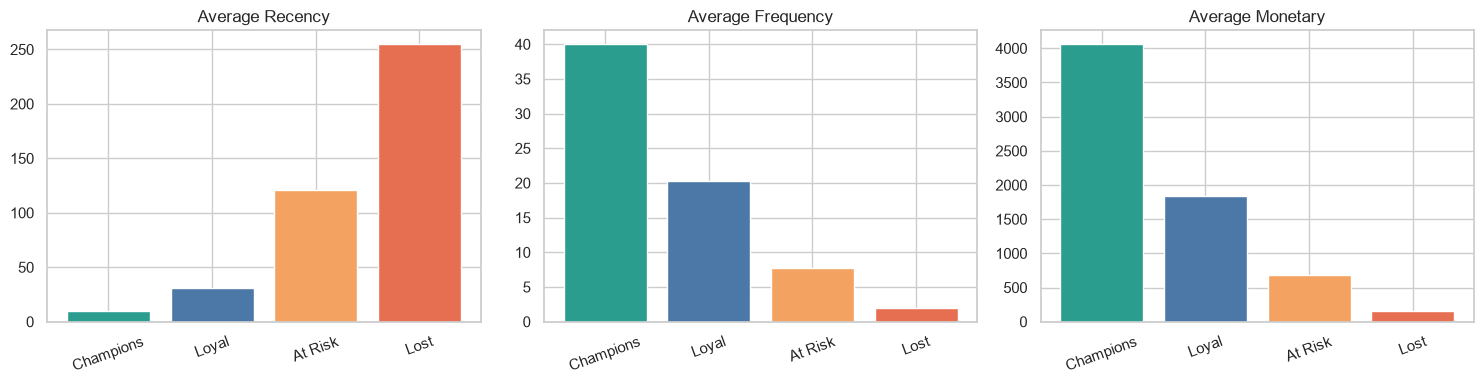

In [18]:
order = ["Champions", "Loyal", "At Risk", "Lost"]
means = df.groupby("segment_name")[features].mean().loc[order]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    ax.bar(order, means[col], color=["#2a9d8f", "#4c78a8", "#f4a261", "#e76f51"])
    ax.set_title(f"Average {col}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## ✅ Summary

- Customers were described using **RFM** features and **standardised** before clustering.
- The **CH Index vs K** plot peaked at **K = 4**, which we chose as the number of segments.
- **K-Means** produced 4 clusters. The **Adjusted Rand Index is close to 1**, so they match the true segments almost perfectly.
- Profiling the clusters gives actionable groups, for example:

| Segment | Typical action |
|---|---|
| 🏆 Champions | Reward programme, early access to new products |
| 💙 Loyal | Upsell and cross-sell |
| ⚠️ At Risk | Reminder emails and targeted discounts |
| 💤 Lost | Win-back campaign or stop spending on them |

## ⚠️ Limitations and next steps
- **Real data is messier.** Segments overlap, so ARI will be lower and CH peaks are less sharp. Real data is usually skewed, so try a `log` transform on Monetary and Frequency first.
- **In production there are no true labels.** You would rely on CH (and also Silhouette or Davies-Bouldin) plus business sense. ARI is mostly useful for benchmarking on labelled data.
- **K-Means assumes round clusters of similar size.** For other shapes try DBSCAN or Gaussian Mixture Models.
- Try it on a real dataset such as the *Online Retail* dataset (UCI) or *Mall Customers* (Kaggle).

---
*Made with scikit-learn. Feel free to fork, tweak and ⭐ the repo!*